# Intro

* How to add an additional classification layer as a "head" of a pretrained LLM
* How to import the IMDB (online movie reviews) database
* That you can create new models by extending base models

# Data

In [29]:
!pip install -U datasets huggingface_hub fsspec

  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)


In [30]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

# Imports

In [31]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from transformers import BertModel, BertTokenizer

In [32]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
bert = BertModel.from_pretrained('bert-base-uncased').to(device)
bert

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
  

In [33]:
bert.embeddings.dropout.p

0.1

In [34]:
tokenizer.vocab_size

30522

More on model inputs and outputs

In [35]:
text = 'Replace me with any text you like.'
tokens = tokenizer(text, return_tensors='pt').to(device)
tokens

{'input_ids': tensor([[ 101, 5672, 2033, 2007, 2151, 3793, 2017, 2066, 1012,  102]],
       device='cuda:0'), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]], device='cuda:0')}

In [36]:
# $ get model output using specific inputs
output = bert(
    input_ids      = tokens['input_ids'],
    attention_mask = tokens['attention_mask']
)

output = bert(**tokens)
output

BaseModelOutputWithPoolingAndCrossAttentions(last_hidden_state=tensor([[[ 0.0965,  0.1224, -0.1108,  ..., -0.3743, -0.2982,  0.4477],
         [ 0.1753, -0.3893,  0.0588,  ...,  0.4928,  0.2224, -0.0216],
         [ 0.1914, -0.5786,  0.2360,  ..., -0.4829,  0.2683,  0.8821],
         ...,
         [ 0.4420,  0.3172,  1.0196,  ..., -0.8215, -0.6848, -0.2039],
         [-0.1163, -0.7017, -0.5098,  ...,  0.1276, -0.6230, -0.5058],
         [ 0.8552,  0.1882, -0.1018,  ...,  0.0646, -0.5835, -0.1768]]],
       device='cuda:0', grad_fn=<NativeLayerNormBackward0>), pooler_output=tensor([[-0.9218, -0.4858, -0.9734,  0.8850,  0.9313, -0.2544,  0.8515,  0.2431,
         -0.9497, -1.0000, -0.8874,  0.9859,  0.9832,  0.6912,  0.9291, -0.8323,
         -0.5453, -0.6562,  0.3008, -0.1131,  0.7066,  1.0000, -0.4118,  0.3926,
          0.6177,  0.9995, -0.8656,  0.9496,  0.9522,  0.6979, -0.6519,  0.3295,
         -0.9945, -0.2477, -0.9612, -0.9935,  0.6465, -0.7298,  0.0884,  0.0989,
         -0.944

In [37]:
dir(output)

['__annotations__',
 '__class__',
 '__class_getitem__',
 '__contains__',
 '__dataclass_fields__',
 '__dataclass_params__',
 '__delattr__',
 '__delitem__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__ior__',
 '__iter__',
 '__le__',
 '__len__',
 '__lt__',
 '__match_args__',
 '__module__',
 '__ne__',
 '__new__',
 '__or__',
 '__post_init__',
 '__reduce__',
 '__reduce_ex__',
 '__replace__',
 '__repr__',
 '__reversed__',
 '__ror__',
 '__setattr__',
 '__setitem__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 'attentions',
 'clear',
 'copy',
 'cross_attentions',
 'fromkeys',
 'get',
 'hidden_states',
 'items',
 'keys',
 'last_hidden_state',
 'move_to_end',
 'past_key_values',
 'pooler_output',
 'pop',
 'popitem',
 'setdefault',
 'to_tuple',
 'update',
 'values']

In [38]:
output['last_hidden_state'].shape

torch.Size([1, 10, 768])

## CLS in BERT

1. BERT adds a special `[CLS]` token at the beginning:

   `[CLS] token1 token2 ... [SEP]`

2. `[CLS]` is converted to a token ID.

3. The token ID is converted to a trainable embedding.

4. The whole sequence goes through the BERT Transformer encoder:

   `[B, S, E] -> Transformer Encoder -> [B, S, E]`

5. Because of self-attention, the hidden representation at position `0` can contain information from the whole sequence.

6. We take the first token representation:

   `cls_hidden = last_hidden_state[:, 0, :]`

   Shape:

   `[B, S, E] -> [B, E]`

7. BERT pooler applies:

   `pooler_output = tanh(Linear(cls_hidden))`

8. `pooler_output` is one vector per input sequence:

   `[B, E]`

9. It can be used for sequence-level tasks such as classification.

**Key distinction:**

- `[CLS]` = special input token
- `cls_hidden` = representation of `[CLS]` after the Transformer
- `pooler_output` = `cls_hidden` after `Linear + tanh`

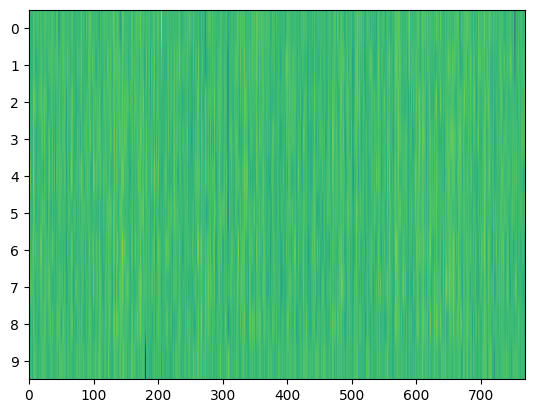

In [39]:
plt.imshow(output['last_hidden_state'].squeeze().detach().cpu(), aspect='auto')
plt.yticks(torch.arange(output['last_hidden_state'].shape[1]))
plt.show()

In [40]:
output['pooler_output'].shape

torch.Size([1, 768])

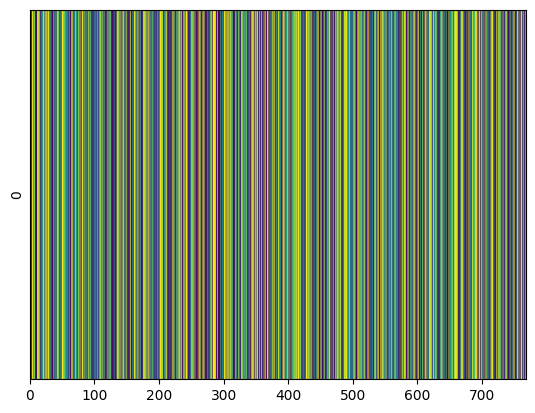

In [41]:
plt.imshow(output['pooler_output'].detach().cpu(), aspect='auto')
plt.ylabel('0')
plt.yticks([])
plt.show()

# Create an LLM model using pretrained BERT with a new head

In [42]:
class BertForBinaryClassification(nn.Module):
  def __init__(self, num_labels=2):
    super().__init__()

    # Load the pretrained BERT model
    self.bert = BertModel.from_pretrained('bert-base-uncased')

    # classification head that converts the 768-d pooled output into 2 final outputs
    self.classifier = nn.Linear(768,2)
    self.dropout    = nn.Dropout(self.bert.embeddings.dropout.p) # 10%

    # initialize the weights and biases
    nn.init.xavier_uniform_(self.classifier.weight)
    nn.init.zeros_(self.classifier.bias)

  def forward(self, input_ids, attention_mask=None, token_type_ids=None):

    # forward pass through the downloaded (pretrained) BERT
    outputs = self.bert(
        input_ids = input_ids,
        attention_mask = attention_mask,
        token_type_ids = token_type_ids
    )

    # extract the pooled output and apply dropout
    pooled_output = self.dropout(outputs.pooler_output)

    # final push through the classification layer
    logits = self.classifier(pooled_output)

    return logits

In [43]:
tokens

{'input_ids': tensor([[ 101, 5672, 2033, 2007, 2151, 3793, 2017, 2066, 1012,  102]],
       device='cuda:0'), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]], device='cuda:0')}

In [44]:
# create an instance of the model and test it
model = BertForBinaryClassification().to(device)

# test the output
tokens = tokenizer(text, return_tensors='pt').to(device)
out = model(**tokens)
out

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tensor([[ 0.3669, -0.2223]], device='cuda:0', grad_fn=<AddmmBackward0>)

# Dataset

In [45]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [46]:
dataset['train'][24000]

{'text': "S.S. Van Dine must have been a shrewd businessman in dealing with Hollywood. Most of the film series' from the studio days were usually confined to one or two studios. But apparently Van Dine must have sold his rights to each book about Philo Vance one at a time. Note that Paramount, MGM, Warner Brothers, and more all released Philo Vance films. Only Tarzan seemed to get around Hollywood more.<br /><br />MGM produced the Garden Murder Case and starred Edmund Lowe as the fashionable detective. Of course MGM had the screen's original Philo under contract at the time, but Bill Powell was busy doing The Thin Man at the time and I guess Louis B. Mayer decided to concentrate him there.<br /><br />Edmund Lowe is a pretty acceptable Philo Vance. Lowe had started out pretty big at the tail end of the silent era with What Price Glory and then with a string of films with Victor McLaglen with their Flagg and Quirt characters. But after McLaglen got his Oscar for The Informer, Lowe seemed

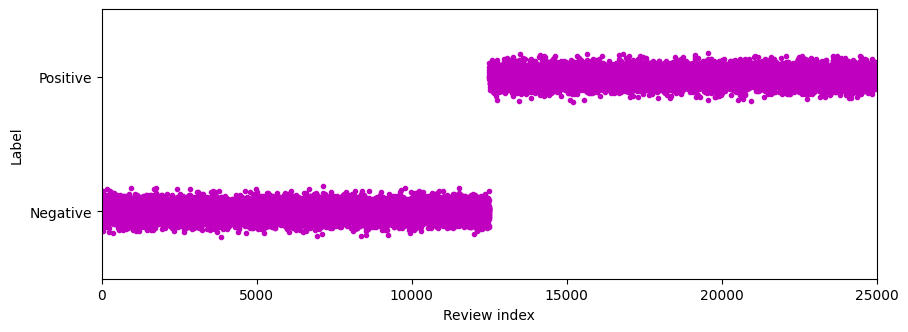

In [47]:
plt.figure(figsize=(10,3.5))
plt.plot(dataset['train']['label'] + np.random.randn(len(dataset['train']))/20,'m.')

plt.gca().set(xlabel='Review index',
              ylabel = 'Label',
              yticks = [0,1],
              yticklabels = ['Negative', 'Positive'],
              xlim = [0, len(dataset['train'])],
              ylim=[-.5,1.5])
plt.show()

Let's take samll sample

In [48]:
dataset['train'].select(range(100))

Dataset({
    features: ['text', 'label'],
    num_rows: 100
})

In [49]:
from datasets import DatasetDict

small_data = DatasetDict({
    split: dataset[split].select(range(10000, 15000)) for split in ['train', 'test']
})
small_data

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 5000
    })
})

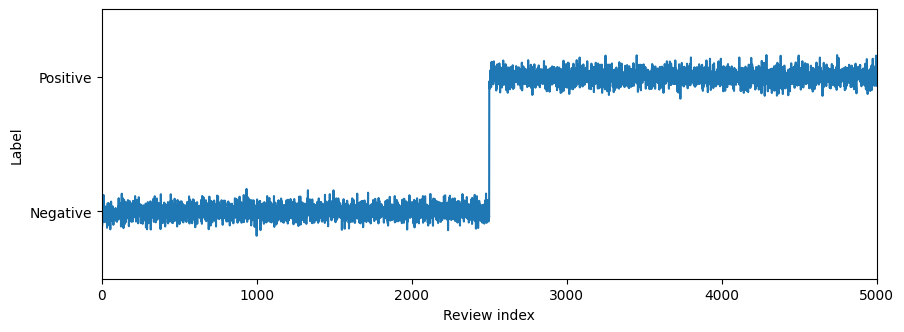

In [50]:
# confirm we still have both categories
plt.figure(figsize=(10, 3.5))

plt.plot(
    small_data['train']['label']
    + np.random.randn(len(small_data['train'])) / 20
)

plt.gca().set(
    xlabel='Review index',
    ylabel='Label',
    yticks=[0, 1],
    yticklabels=['Negative', 'Positive'],
    xlim=[0, len(small_data['train'])],
    ylim=[-.5, 1.5]
)

plt.show()

# Tokenizing the text with padding

In [51]:
first_try = tokenizer(dataset['train'][0]['text'])

# but this is better b/c reviews have differing lenghts
better = tokenizer(
    dataset['train'][0]['text'], # the text to tokenize
    max_length = 512,
    padding    = 'max_length', # using pad_token to reach max_len
    truncation = True
)

print(f'Naive\' tokenization (N = {len(first_try["input_ids"])})')
print(f'{first_try['input_ids']}')

print(f"\nBetter tokenization (N={len(better['input_ids'])}):")
print(f"{better['input_ids']}")

Naive' tokenization (N = 363)
[101, 1045, 12524, 1045, 2572, 8025, 1011, 3756, 2013, 2026, 2678, 3573, 2138, 1997, 2035, 1996, 6704, 2008, 5129, 2009, 2043, 2009, 2001, 2034, 2207, 1999, 3476, 1012, 1045, 2036, 2657, 2008, 2012, 2034, 2009, 2001, 8243, 2011, 1057, 1012, 1055, 1012, 8205, 2065, 2009, 2412, 2699, 2000, 4607, 2023, 2406, 1010, 3568, 2108, 1037, 5470, 1997, 3152, 2641, 1000, 6801, 1000, 1045, 2428, 2018, 2000, 2156, 2023, 2005, 2870, 1012, 1026, 7987, 1013, 1028, 1026, 7987, 1013, 1028, 1996, 5436, 2003, 8857, 2105, 1037, 2402, 4467, 3689, 3076, 2315, 14229, 2040, 4122, 2000, 4553, 2673, 2016, 2064, 2055, 2166, 1012, 1999, 3327, 2016, 4122, 2000, 3579, 2014, 3086, 2015, 2000, 2437, 2070, 4066, 1997, 4516, 2006, 2054, 1996, 2779, 25430, 14728, 2245, 2055, 3056, 2576, 3314, 2107, 2004, 1996, 5148, 2162, 1998, 2679, 3314, 1999, 1996, 2142, 2163, 1012, 1999, 2090, 4851, 8801, 1998, 6623, 7939, 4697, 3619, 1997, 8947, 2055, 2037, 10740, 2006, 4331, 1010, 2016, 2038, 3348, 2007,

In [52]:
def tokenize_function(one_sample):
  return tokenizer(
      one_sample['text'],
      max_length = 512,
      padding = 'max_length',
      truncation = True # truncate sequences longer than max_length
  )

# apply tokenization func
tokenized_dataset = small_data.map(tokenize_function, batched = True)
tokenized_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5000
    })
})

# DataLoaders

In [53]:
# remove text pair
tokenized_dataset = tokenized_dataset.remove_columns(['text'])

# change format to pytorch tensors
tokenized_dataset.set_format('torch', columns = ['input_ids', 'attention_mask', 'label'])

# create DataLoaders for training and testing
train_dataloader = DataLoader(tokenized_dataset['train'], shuffle=True, batch_size = 32)
test_dataloader  = DataLoader(tokenized_dataset['test'], batch_size = 32)

In [54]:
X = next(iter(train_dataloader))
X

{'label': tensor([0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0,
         1, 0, 1, 1, 0, 1, 1, 1]),
 'input_ids': tensor([[  101,  2045,  2074,  ...,     0,     0,     0],
         [  101,  1012,  1012,  ...,     0,     0,     0],
         [  101,  1996, 18458,  ...,     0,     0,     0],
         ...,
         [  101,  2129,  2064,  ...,     0,     0,     0],
         [  101,  1045,  1005,  ...,     0,     0,     0],
         [  101,  1037,  4086,  ...,     0,     0,     0]]),
 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         ...,
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0]])}

# Fine-Tune

In [55]:
# optimizer and loss
optimizer = torch.optim.AdamW(model.parameters(), lr = 1e-5)
loss_fn = nn.CrossEntropyLoss() # ce loss for multi-class classification

In [56]:
# get a batch of data
batch = next(iter(train_dataloader))

# move it to GPU
tokenz  = batch['input_ids'].to(device)
att_msk = batch['attention_mask'].to(device)
labels  = batch['label'].to(device)

# clear the previous gradeints
optimizer.zero_grad()

# forward pass and get model preds
logits = model(tokenz, attention_mask=att_msk)
pred_labels = torch.argmax(logits, dim=1)

# calculate and store loss + avg acc
loss = loss_fn(logits, labels)
train_acc = (pred_labels == labels).sum().item()/train_dataloader.batch_size

# backward pass
loss.backward()

# update the weights and teh lr
optimizer.step()

# Eval

In [57]:
print(f'Logits are of size {logits.shape} and are:\n', logits)

print('Model predictions:', pred_labels)
print('True labels:', labels)

accuracy = (pred_labels == labels).sum()/train_dataloader.batch_size

print(f'Accuracy is {100*accuracy:.1f}%')

Logits are of size torch.Size([32, 2]) and are:
 tensor([[-0.0557,  0.8348],
        [ 0.0793, -0.3328],
        [-0.0762,  0.4908],
        [ 0.1920,  0.2358],
        [-0.3566,  0.2351],
        [-0.0664,  0.2054],
        [-0.7526,  0.3708],
        [-0.2344, -0.1037],
        [ 0.0998,  0.3939],
        [-0.5751,  0.4669],
        [ 0.1346,  0.1022],
        [-0.1588, -0.4969],
        [-0.1182, -0.4135],
        [-0.1884,  0.4905],
        [-0.2846,  0.1771],
        [-0.2720,  0.3151],
        [-0.7837,  0.7044],
        [-1.0268,  0.5535],
        [-0.3631,  0.6064],
        [-0.2892,  0.2818],
        [ 0.2343, -0.1145],
        [ 0.3880,  0.2690],
        [-0.6178,  0.1793],
        [ 0.0780,  0.2105],
        [-0.8712, -0.2249],
        [ 0.0614,  0.1266],
        [ 0.1602, -0.2646],
        [-0.5406, -0.0933],
        [ 0.0499,  0.4235],
        [ 0.1753,  0.3137],
        [-0.2812, -0.6290],
        [-0.4586,  0.1413]], device='cuda:0', grad_fn=<AddmmBackward0>)
Model predi

# Sumup

* Base models are very versatile, and you can use them in many ways
* Procedures for importing datasets and models from 3rd party platforms can change; be prepared to modify your code
* Be mindful of the appropriate loss function, it's not always NLLLoss